# Stage 9 — Threshold Calibration, Detection Evaluation & Severity Estimation

**Purpose:** Continue from the existing Stage 8 corrected outputs. This notebook does **not** rerun Stage 8, rebuild the graph, retrain DGI-GCN, or regenerate attacks.

## Methodological decision
- Retain the manuscript's Euclidean anomaly score: `S_i = ||h_i - μ||₂`.
- Calibrate the decision threshold using the **95th percentile of clean validation scores**.
- Freeze that threshold and apply it unchanged to validation and test samples.
- Retain the manuscript's min–max severity formula, with the minimum and maximum fixed from validation scores and reused for test scores.
- Report severity as a **relative anomaly-severity score**, not as a direct measure of clinical disease severity or attack strength.

The former fixed threshold `0.4` will be documented as unsuitable for the current embedding scale. Do not manually change values in this notebook.


## Step 1 — Upload the existing Stage 8 corrected output ZIP

Upload **`Stage8_Corrected_Outputs.zip`** (the ZIP you already downloaded from Stage 8).

You do not need to upload Stage 5, Stage 6, Stage 7, or Stage 8A files for this stage.


In [1]:
from google.colab import files
uploaded = files.upload()

import os, zipfile, glob, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score, roc_auc_score

zip_candidates = [name for name in uploaded if name.lower().endswith('.zip')]
if not zip_candidates:
    raise FileNotFoundError("Please upload Stage8_Corrected_Outputs.zip.")

zip_path = zip_candidates[0]
extract_dir = "/content/stage9_stage8_inputs"
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zf:
    zf.extractall(extract_dir)

csv_candidates = glob.glob(os.path.join(extract_dir, "**", "stage8_anomaly_scores.csv"), recursive=True)
if not csv_candidates:
    raise FileNotFoundError("stage8_anomaly_scores.csv was not found inside the uploaded ZIP.")

df = pd.read_csv(csv_candidates[0])
required = {"split", "attack", "sample_type", "true_detection_label", "attack_success", "anomaly_score"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns in Stage 8 output: {sorted(missing)}")

df["anomaly_score"] = pd.to_numeric(df["anomaly_score"], errors="coerce")
df = df.dropna(subset=["anomaly_score"]).copy()
df["true_detection_label"] = df["true_detection_label"].astype(int)
df["attack_success"] = df["attack_success"].astype(str).str.lower().isin(["true", "1", "yes"])

print("Loaded Stage 8 score rows:", len(df))
print("\nRows by split and sample type:")
display(df.groupby(["split", "sample_type"]).size().rename("rows").reset_index())
print("\nAttacks:", sorted(df["attack"].unique()))


Saving Stage8_Corrected_Outputs.zip to Stage8_Corrected_Outputs.zip
Loaded Stage 8 score rows: 35364

Rows by split and sample type:


,split,sample_type,rows
0,test,adversarial,2379
1,test,clean_paired,2379
2,train,adversarial,12909
3,train,clean_paired,12909
4,validation,adversarial,2394
5,validation,clean_paired,2394



Attacks: ['CW_L2', 'FGSM', 'PGD']


## Step 2 — Calibrate the threshold using clean validation samples only

The threshold is the 95th percentile of validation clean scores. This targets approximately 5% false positives on the calibration set by construction; the actual test false-positive rate must be measured independently.

This is a new, explicitly documented calibration procedure. It is not the old fixed threshold of 0.4.


In [2]:
val_clean = df[(df["split"].str.lower() == "validation") &
               (df["sample_type"].str.lower() == "clean_paired")]

if len(val_clean) == 0:
    raise ValueError("No validation clean_paired scores found.")

CALIBRATION_PERCENTILE = 95.0
tau_calibrated = float(np.percentile(val_clean["anomaly_score"].to_numpy(), CALIBRATION_PERCENTILE))

print(f"Calibrated threshold (validation clean {CALIBRATION_PERCENTILE:.1f}th percentile): {tau_calibrated:.8f}")
print(f"Validation clean samples used: {len(val_clean)}")
print(f"Validation clean fraction above threshold: {(val_clean['anomaly_score'] > tau_calibrated).mean():.4f}")


Calibrated threshold (validation clean 95.0th percentile): 3.78909577
Validation clean samples used: 2394
Validation clean fraction above threshold: 0.0501


## Step 3 — Evaluate detection using the frozen threshold

The threshold is not re-tuned on the test set. Metrics are calculated separately for FGSM, PGD and CW-L2. Only adversarial examples marked successful in the Stage 7 output are counted as positive attack samples.


In [3]:
def detection_metrics(frame, split_name, attack_name):
    clean = frame[frame["sample_type"].str.lower() == "clean_paired"].copy()
    adv = frame[(frame["sample_type"].str.lower() == "adversarial") & frame["attack_success"]].copy()
    if len(clean) == 0 or len(adv) == 0:
        return None

    y_true = np.concatenate([np.zeros(len(clean), dtype=int), np.ones(len(adv), dtype=int)])
    scores = np.concatenate([clean["anomaly_score"].to_numpy(), adv["anomaly_score"].to_numpy()])
    y_pred = (scores > tau_calibrated).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    try:
        auc = roc_auc_score(y_true, scores)
    except Exception:
        auc = np.nan

    return {
        "split": split_name, "attack": attack_name, "threshold": tau_calibrated,
        "clean_samples": len(clean), "successful_adversarial_samples": len(adv),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
        "AUC": auc,
        "false_positive_rate": fp / (fp + tn) if (fp + tn) else np.nan
    }

metric_rows = []
for split_name in ["validation", "test"]:
    split_df = df[df["split"].str.lower() == split_name]
    for attack_name in sorted(split_df["attack"].unique()):
        row = detection_metrics(split_df[split_df["attack"] == attack_name], split_name, attack_name)
        if row:
            metric_rows.append(row)

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df.round(4))


,split,attack,threshold,clean_samples,successful_adversarial_samples,TN,FP,FN,TP,precision,recall,f1,accuracy,AUC,false_positive_rate
0,validation,CW_L2,3.7891,798,798,768,30,798,0,0.0000,0.0000,0.0000,0.4812,0.4210,0.0376
1,validation,FGSM,3.7891,798,797,755,43,620,177,0.8045,0.2221,0.3481,0.5843,0.8344,0.0539
2,validation,PGD,3.7891,798,797,751,47,24,773,0.9427,0.9699,0.9561,0.9555,0.9855,0.0589
3,test,CW_L2,3.7891,793,793,778,15,793,0,0.0000,0.0000,0.0000,0.4905,0.4261,0.0189
4,test,FGSM,3.7891,793,793,754,39,615,178,0.8203,0.2245,0.3525,0.5876,0.8414,0.0492
5,test,PGD,3.7891,793,793,745,48,22,771,0.9414,0.9723,0.9566,0.9559,0.9849,0.0605


## Step 4 — Calculate relative anomaly severity

The manuscript's min–max formula is retained:

`Severity = ((S_i − S_min) / (S_max − S_min)) × 100`

To avoid using test data to set the scale, `S_min` and `S_max` are obtained from all validation scores (clean paired samples and successful adversarial samples). The same bounds are applied unchanged to test scores. Values outside the validation range are clipped to 0–100 and counted in the output.

**Interpretation:** This is relative anomaly severity on the calibrated score scale. It should not be described as clinical Alzheimer’s severity or as a direct physical perturbation magnitude.


In [4]:
val_all = df[df["split"].str.lower() == "validation"].copy()
val_success_adv = val_all[(val_all["sample_type"].str.lower() == "adversarial") & val_all["attack_success"]]
val_clean_all = val_all[val_all["sample_type"].str.lower() == "clean_paired"]
val_for_scale = pd.concat([val_clean_all, val_success_adv], ignore_index=True)

if len(val_for_scale) == 0:
    raise ValueError("No validation scores available for severity scaling.")

S_min = float(val_for_scale["anomaly_score"].min())
S_max = float(val_for_scale["anomaly_score"].max())
if S_max <= S_min:
    raise ValueError("Validation score range is zero; min-max severity cannot be calculated.")

df["severity_unclipped"] = ((df["anomaly_score"] - S_min) / (S_max - S_min)) * 100.0
df["severity_score"] = df["severity_unclipped"].clip(0, 100)
df["severity_clipped"] = (df["severity_unclipped"] < 0) | (df["severity_unclipped"] > 100)

print(f"Validation severity bounds: S_min={S_min:.8f}, S_max={S_max:.8f}")
print("Test scores outside validation bounds (clipped):",
      int(df.loc[df["split"].str.lower() == "test", "severity_clipped"].sum()))


Validation severity bounds: S_min=0.99114269, S_max=11.22769356
Test scores outside validation bounds (clipped): 3


## Step 5 — Summarise severity by attack and sample type

The table reports mean, median and standard deviation of relative anomaly severity. Clean and adversarial values are shown separately. Adversarial rows are restricted to successful attacks.


,split,attack,sample_type,n,mean_severity,median_severity,std_severity
0,test,CW_L2,adversarial,793,5.237,5.043,2.440
1,test,CW_L2,clean_paired,793,8.471,5.758,7.455
2,test,FGSM,adversarial,793,20.489,20.033,8.314
3,test,FGSM,clean_paired,793,9.478,5.925,9.155
4,test,PGD,adversarial,793,61.757,65.937,16.093
5,test,PGD,clean_paired,793,9.984,6.049,11.287
6,validation,CW_L2,adversarial,798,5.521,5.269,2.674
7,validation,CW_L2,clean_paired,798,8.799,6.023,7.618
8,validation,FGSM,adversarial,797,20.533,20.314,8.353
9,validation,FGSM,clean_paired,798,9.705,6.237,8.968


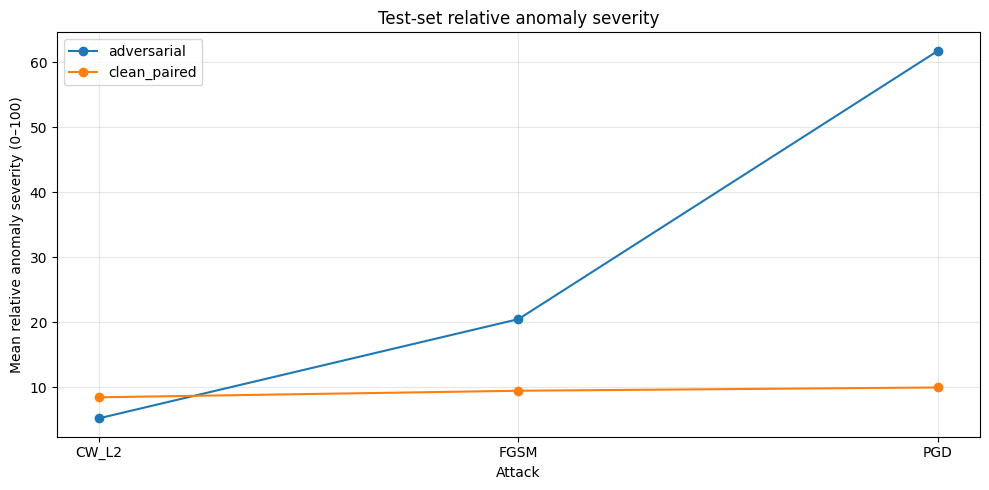

In [5]:
severity_source = df[
    (df["sample_type"].str.lower() == "clean_paired") |
    ((df["sample_type"].str.lower() == "adversarial") & df["attack_success"])
].copy()

severity_summary = (
    severity_source[severity_source["split"].str.lower().isin(["validation", "test"])]
    .groupby(["split", "attack", "sample_type"])["severity_score"]
    .agg(n="count", mean_severity="mean", median_severity="median", std_severity="std")
    .reset_index()
)
display(severity_summary.round(3))

plt.figure(figsize=(10, 5))
plot_data = severity_summary[severity_summary["split"] == "test"]
for sample_type in sorted(plot_data["sample_type"].unique()):
    sub = plot_data[plot_data["sample_type"] == sample_type]
    plt.plot(sub["attack"], sub["mean_severity"], marker="o", label=sample_type)
plt.ylabel("Mean relative anomaly severity (0–100)")
plt.xlabel("Attack")
plt.title("Test-set relative anomaly severity")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Step 6 — Save Stage 9 outputs

The ZIP will contain the calibrated threshold, detection metrics, severity summaries and per-sample scores. Use these outputs to update the manuscript tables. Do not copy the earlier manuscript metrics unless they are reproduced by these results.


In [6]:
out_dir = "/content/Stage9_Outputs"
os.makedirs(out_dir, exist_ok=True)

metrics_df.to_csv(os.path.join(out_dir, "stage9_detection_metrics_calibrated_threshold.csv"), index=False)
severity_summary.to_csv(os.path.join(out_dir, "stage9_severity_summary.csv"), index=False)
df.to_csv(os.path.join(out_dir, "stage9_all_sample_scores_and_severity.csv"), index=False)

config = {
    "source": "Stage8_Corrected_Outputs.zip",
    "anomaly_score": "Euclidean distance from clean training centroid as produced by Stage 8",
    "threshold_method": "95th percentile of validation clean_paired anomaly scores",
    "calibrated_threshold": tau_calibrated,
    "threshold_frozen_for_test": True,
    "severity_formula": "((S_i - S_min) / (S_max - S_min)) * 100",
    "severity_S_min_validation": S_min,
    "severity_S_max_validation": S_max,
    "severity_bounds_source": "All validation clean_paired and successful adversarial scores",
    "severity_clipping": "Clip to [0,100]; report count outside validation bounds",
    "interpretation": "Relative anomaly severity, not clinical disease severity or direct perturbation magnitude"
}
with open(os.path.join(out_dir, "stage9_method_config.json"), "w") as f:
    json.dump(config, f, indent=2)

zip_out = "/content/Stage9_Outputs.zip"
with zipfile.ZipFile(zip_out, "w", zipfile.ZIP_DEFLATED) as zf:
    for root, _, filenames in os.walk(out_dir):
        for filename in filenames:
            full = os.path.join(root, filename)
            zf.write(full, arcname=os.path.relpath(full, out_dir))

print("Created:", zip_out)
files.download(zip_out)


Created: /content/Stage9_Outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>